A defasagem é:  -6


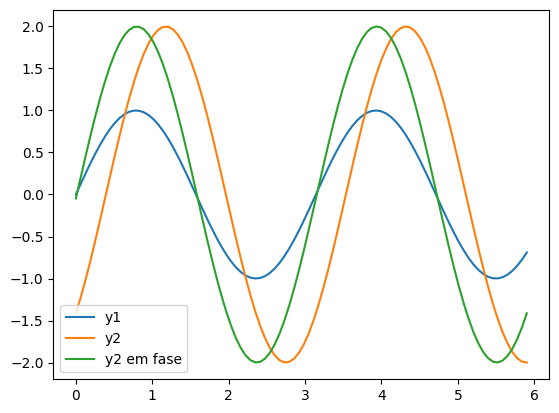

In [13]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

# Supondo que seus dados estejam no seguinte formato:
xx = np.linspace(0, 2*np.pi, 100)
yy1 = np.sin(2*xx)
yy2 = 2*np.sin(2*xx - np.pi/4)
dados = {
    'x': xx,
    'y1': yy1,  # exemplo de onda senoidal
    'y2': yy2,  # exemplo de onda senoidal deslocada
}

# é só aprender a ler um .dat ou .xlsx em um dataframe.... molezinha agora
df = pd.DataFrame(dados)

# Computando a correlação cruzada
corr = np.correlate(df['y1'], df['y2'], "full")

# A defasagem é a posição da correlação máxima
d = corr.argmax() - (len(df['y1']) - 1)

print("A defasagem é: ", d)

# Agora, deslocando a onda y2
df['y2_shifted'] = df['y2'].shift(d)

# Removendo as linhas com valores NaN resultantes do deslocamento
df = df.dropna()

# Fazendo um gráfico das ondas y1 e y2_shifted
plt.plot(df['x'], df['y1'], label='y1')
plt.plot(df['x'], df['y2'], label='y2')
plt.plot(df['x'], df['y2_shifted'], label='y2 em fase')
plt.legend()
plt.show()
